# Cek Stasioneritas: Jumlah Kunjungan Pasien (`jk`)

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": .3})
S = 7  # periode musiman: data harian, pola mingguan

## 1. Muat data & cek kualitas

In [2]:
df = pd.read_excel("../data/jk_pasien.xlsx")
df["tanggal"] = pd.to_datetime(df["tanggal"])
df = df.sort_values("tanggal").set_index("tanggal")
y = df["jk"].astype(float)

y = y.asfreq("D")  # set frekuensi harian eksplisit (dibutuhkan statsmodels)
y.describe().round(1).to_frame("jk")

,jk
count,1382.0
mean,808.0
std,377.9
min,113.0
25%,570.5
50%,928.5
75%,1071.8
max,1760.0


## 2. Plot deret waktu

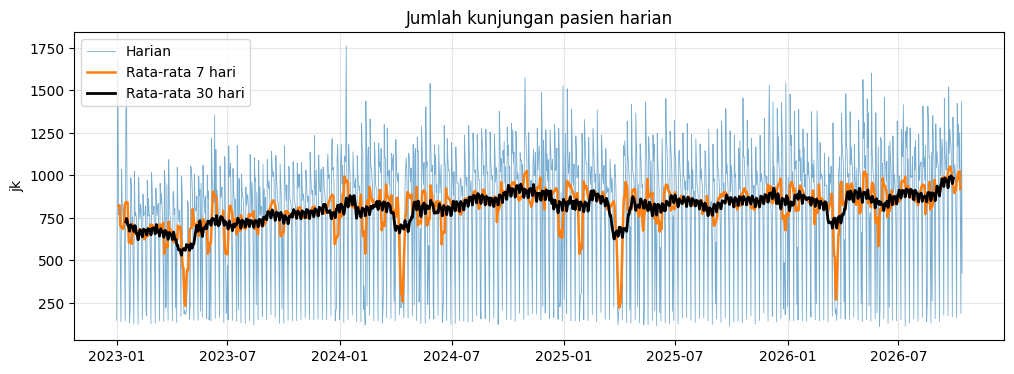

In [3]:
fig, ax = plt.subplots()
ax.plot(y, lw=.6, alpha=.6, label="Harian")
ax.plot(y.rolling(7, center=True).mean(), lw=1.8, label="Rata-rata 7 hari")
ax.plot(y.rolling(30, center=True).mean(), lw=2, color="k", label="Rata-rata 30 hari")
ax.set(title="Jumlah kunjungan pasien harian", ylabel="jk")
ax.legend()
plt.show()

### Pola musiman mingguan

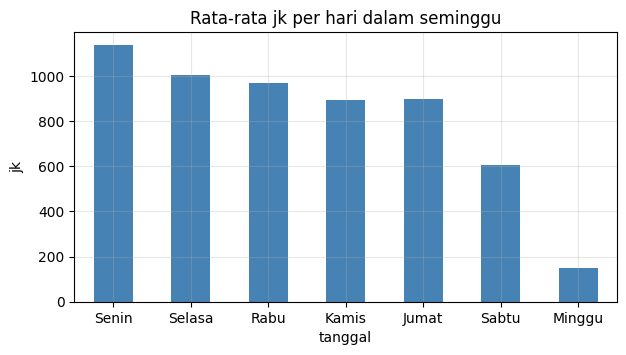

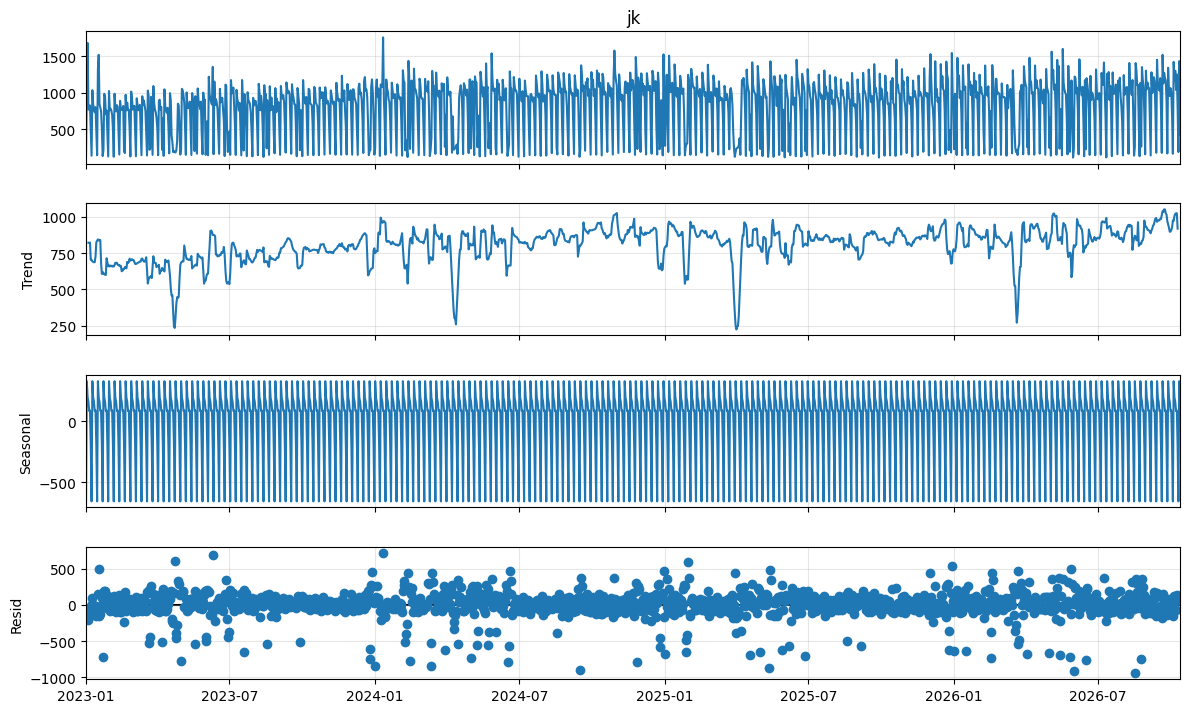

In [4]:
nama_hari = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
rata_hari = y.groupby(y.index.dayofweek).mean()
ax = rata_hari.plot.bar(figsize=(7, 3.5), color="steelblue")
ax.set_xticklabels(nama_hari, rotation=0)
ax.set(title="Rata-rata jk per hari dalam seminggu", ylabel="jk")
plt.show()

dekom = seasonal_decompose(y, model="additive", period=S)
fig = dekom.plot()
fig.set_size_inches(12, 8)
plt.show()

## 3. Uji stasioneritas

Dilakukan dua uji yaitu uji ADF dan uji KPSS.

Uji ADF stasioner jika p-value < 0,05

Uji KPSS stasioner jika p-value ≥ 0,05

Kesimpulan "stasioner" dipakai hanya jika kedua uji sepakat.

In [23]:
def uji_stasioneritas(series, nama, alpha=0.05):
    x = series.dropna()
    adf_stat, adf_p, *_ = adfuller(x, autolag="AIC")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_stat, kpss_p, *_ = kpss(x, regression="c", nlags="auto")
    adf_ok = adf_p < alpha
    kpss_ok = kpss_p >= alpha
    if adf_ok and kpss_ok:
        simpul = "Stasioner"
    elif not adf_ok and not kpss_ok:
        simpul = "Tidak stasioner"
    else:
        simpul = "Ambigu (uji tidak sepakat)"
    return {"Deret": nama, "n": len(x),
            "ADF stat": adf_stat, "ADF p": adf_p,
            "KPSS stat": kpss_stat, "KPSS p": kpss_p,
            "Kesimpulan": simpul}

hasil = [uji_stasioneritas(y, "Asli")]
pd.DataFrame(hasil).round(4)

,Deret,n,ADF stat,ADF p,KPSS stat,KPSS p,Kesimpulan
0,Asli,1382,-5.1132,0.0,1.9244,0.01,Ambigu (uji tidak sepakat)


## 4. Differencing

Empat kandidat:
- **d = 1**: selisih biasa `y_t - y_{t-1}` (menghilangkan tren)
- **D = 1**: selisih musiman `y_t - y_{t-7}` (menghilangkan pola mingguan)
- **d = 1 & D = 1**: keduanya

In [20]:
y_d1   = y.diff(1)
y_D1   = y.diff(S)
y_d1D1 = y.diff(1).diff(S)

hasil = [
    uji_stasioneritas(y,      "Asli"),
    uji_stasioneritas(y_d1,   "d=1"),
    uji_stasioneritas(y_D1,   f"D=1 (lag {S})"),
    uji_stasioneritas(y_d1D1, f"d=1, D=1 (lag {S})"),
]
ringkasan = pd.DataFrame(hasil).set_index("Deret")
ringkasan.round(4)

,n,ADF stat,ADF p,KPSS stat,KPSS p,Kesimpulan
Deret,,,,,,
Asli,1382,-5.1132,0.0,1.9244,0.01,Ambigu (uji tidak sepakat)
d=1,1381,-13.7822,0.0,0.2094,0.10,Stasioner
D=1 (lag 7),1375,-12.9414,0.0,0.0050,0.10,Stasioner
"d=1, D=1 (lag 7)",1374,-14.9459,0.0,0.1006,0.10,Stasioner


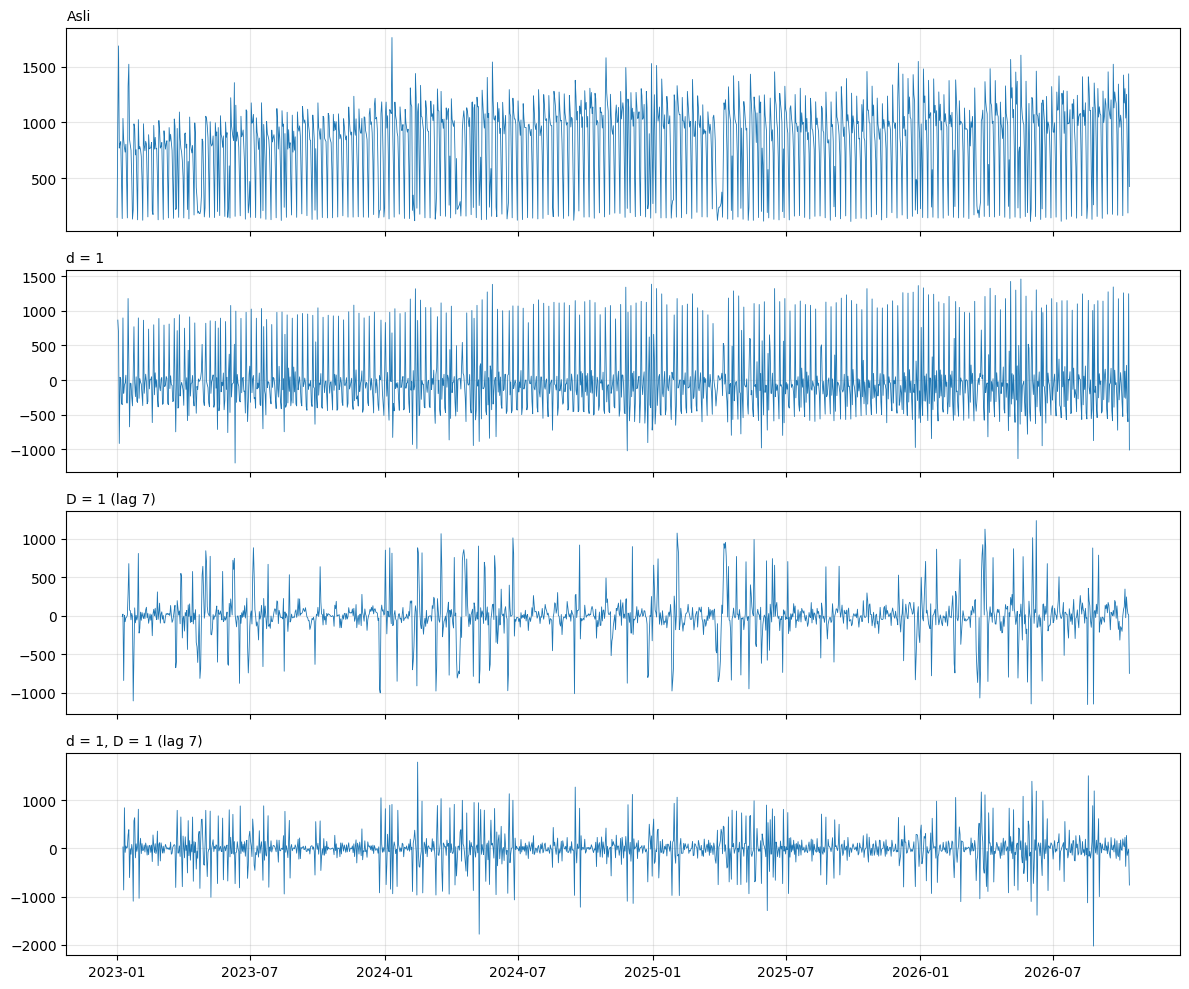

In [21]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, (s, jdl) in zip(axes, [(y, "Asli"), (y_d1, "d = 1"),
                               (y_D1, f"D = 1 (lag {S})"), (y_d1D1, f"d = 1, D = 1 (lag {S})")]):
    ax.plot(s, lw=.6)
    ax.set_title(jdl, loc="left", fontsize=10)
plt.tight_layout()
plt.show()